In [52]:
import kagglehub
import matplotlib.pyplot as plt


# Download latest version
path = kagglehub.dataset_download("vedauv/what-makes-a-yt-video-go-viral-12000-vids")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'what-makes-a-yt-video-go-viral-12000-vids' dataset.
Path to dataset files: /kaggle/input/what-makes-a-yt-video-go-viral-12000-vids


In [53]:
import torch
import os             # Para manejar rutas de archivos
import pandas as pd

In [54]:
import os             # os: para trabajar con carpetas y archivos del sistema
import pandas as pd   # pandas: LA librería para manejar tablas de datos en Python; se abrevia "pd" por convención

archivos = os.listdir(path)   # listdir = "listar directorio": devuelve los nombres de los archivos dentro de la carpeta descargada
print("Archivos encontrados:", archivos)

# Buscamos el archivo que termine en .csv de manera dinámica
archivo_csv = [f for f in archivos if f.endswith('.csv')][0]

df = pd.read_csv(os.path.join(path, archivo_csv))   # Cargamos el archivo CSV correcto
                                                    # os.path.join une la carpeta y el nombre del archivo en una ruta completa
                                                    # "df" es el nombre típico para un DataFrame

print("Dimensiones del DataFrame:", df.shape)   # shape = (número de filas, número de columnas)
df.info()         # info muestra cada columna: su nombre, su tipo de dato y cuántos valores NO están vacíos

Archivos encontrados: ['datasheet.md', 'README.md', 'viral_videos.csv']
Dimensiones del DataFrame: (12000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   video_id            12000 non-null  object
 1   category            12000 non-null  object
 2   duration_sec        12000 non-null  int64 
 3   title_length        12000 non-null  int64 
 4   thumbnail_face      12000 non-null  int64 
 5   upload_hour         12000 non-null  int64 
 6   upload_day          12000 non-null  object
 7   tags_count          12000 non-null  int64 
 8   description_length  12000 non-null  int64 
 9   subscriber_count    12000 non-null  int64 
 10  views               12000 non-null  int64 
 11  likes               12000 non-null  int64 
 12  comments            12000 non-null  int64 
 13  shares              12000 non-null  int64 
 14  viral  

In [55]:
with open(os.path.join(path, "README.md"))as f:
  print (f.read())
print("=" * 60)

with open(os.path.join(path, "datasheet.md"))as f:
  print(f.read())


# What Makes a Video Go Viral? — 12,000 Videos with Engagement Metrics

## What is this?

A synthetic YouTube-style dataset with 12,000 videos across 15 categories. Includes metadata, channel size, engagement metrics, and a clear viral target.

## Why should you use it?

- **Clean, complete data** — no missing values
- **Defined target** — `viral` (top 20% of views) for classification, `views` for regression
- **Realistic distributions** — category-specific view and engagement patterns
- **Multiple tasks** — classification, regression, feature importance
- **Universal appeal** — anyone who watches YouTube can relate

## Columns

| Column | Description |
|--------|-------------|
| `video_id` | Unique identifier |
| `category` | Content category (15 categories) |
| `duration_sec` | Video length in seconds |
| `title_length` | Characters in title |
| `thumbnail_face` | 1 if thumbnail contains a face |
| `upload_hour` | Hour of day uploaded (0-23) |
| `upload_day` | Day of week uploaded |


In [56]:
print(df["viral"].value_counts())                  # value_counts cuenta cuántas veces aparece cada valor en la columna: cuántos 0 y cuántos 1
print(df["viral"].value_counts(normalize=True))    # normalize=True da proporciones en vez de conteos (0.8 = 80%)

viral
0    9600
1    2400
Name: count, dtype: int64
viral
0    0.8
1    0.2
Name: proportion, dtype: float64


In [57]:
df.describe()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,12000.000000
mean,631.619583,54.524000,0.400250,11.539417,14.586833,508.919417,1.009487e+06,7.677524e+05,3.750578e+04,4.739626e+03,9.503240e+03,0.200000
std,285.825411,14.950788,0.489969,6.914424,7.741422,287.212933,2.585562e+06,3.526908e+06,1.823115e+05,2.331387e+04,4.644499e+04,0.400017
min,30.000000,10.000000,0.000000,0.000000,0.000000,0.000000,3.636000e+03,1.390000e+02,6.000000e+00,0.000000e+00,1.000000e+00,0.000000
25%,408.000000,45.000000,0.000000,5.000000,9.000000,300.000000,1.585215e+05,6.123550e+04,2.790000e+03,3.167500e+02,6.417500e+02,0.000000
50%,614.000000,55.000000,0.000000,12.000000,14.000000,504.000000,3.813820e+05,1.852680e+05,8.751500e+03,1.018000e+03,2.050500e+03,0.000000
75%,822.000000,65.000000,1.000000,18.000000,20.000000,709.000000,9.298448e+05,5.569705e+05,2.657125e+04,3.207250e+03,6.527250e+03,0.000000
max,1960.000000,109.000000,1.000000,23.000000,44.000000,1618.000000,1.000000e+08,1.994657e+08,1.159287e+07,1.116186e+06,2.367174e+06,1.000000


In [58]:
tasa_viral= df.groupby("category")["viral"].mean()

tasa_viral.sort_values(ascending = False)

,viral
category,
Music,0.572165
Comedy,0.352258
Sports,0.275434
Gaming,0.242875
Beauty,0.233782
Tech,0.190534
News,0.185455
Cooking,0.171285
Finance,0.152253


In [59]:
print (df.shape)
print(df.columns.tolist())

(12000, 15)
['video_id', 'category', 'duration_sec', 'title_length', 'thumbnail_face', 'upload_hour', 'upload_day', 'tags_count', 'description_length', 'subscriber_count', 'views', 'likes', 'comments', 'shares', 'viral']


X (lo que el modelo puede ver)	category, duration_sec, title_length, thumbnail, upload_hour, upload_day, tags_count, description_length, subscriber_count
y (lo que predice)	viral
Prohibidas (fuga de datos)	views, likes, comments, shares

In [60]:
features = ["category", "duration_sec", "title_length", "thumbnail_face",   # lista con las columnas permitidas (las de "antes")
            "upload_hour", "upload_day", "tags_count",
            "description_length", "subscriber_count"]
print(df[features].dtypes)    # dtypes = el tipo de dato de cada columna: int64/float64 = número, object = texto, bool = verdadero/falso

category              object
duration_sec           int64
title_length           int64
thumbnail_face         int64
upload_hour            int64
upload_day            object
tags_count             int64
description_length     int64
subscriber_count       int64
dtype: object


In [61]:
from pandas.core.indexes import category
x = df[features]
y = df["viral"]

x = pd.get_dummies(x,
                   columns=["category", "upload_day"],)
print(x.shape)
print(x.columns.tolist())

(12000, 29)
['duration_sec', 'title_length', 'thumbnail_face', 'upload_hour', 'tags_count', 'description_length', 'subscriber_count', 'category_Beauty', 'category_Comedy', 'category_Cooking', 'category_DIY', 'category_Education', 'category_Finance', 'category_Fitness', 'category_Gaming', 'category_Music', 'category_News', 'category_Science', 'category_Sports', 'category_Tech', 'category_Travel', 'category_Vlog', 'upload_day_Fri', 'upload_day_Mon', 'upload_day_Sat', 'upload_day_Sun', 'upload_day_Thu', 'upload_day_Tue', 'upload_day_Wed']


In [62]:
prueba = df[["duration_sec", "tags_count"]]   # corchetes de afuera = "dame de df…"; corchetes de adentro = la lista de columnas
print(prueba.shape)                            # (12000, 2): todos los videos, solo 2 columnas
prueba.head()                                  # muestra los primeros 5 videos con esas 2 columnas


(12000, 2)


,duration_sec,tags_count
0,517,27
1,495,10
2,311,13
3,590,17
4,380,0


In [63]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size = 0.2,
    random_state=42,
    stratify = y
)
print(x_train.shape) #filas y columnas de mi 80% correspondiente a train
print(y_train.shape) #filas de mi 80% correspondiente a train
print(x_test.shape)  #filas y columnas de mi 20% correspondiente a test
print(y_test.shape)  #filas de mi 20% correspondiente a test
print(y_test.mean())
print(y_train.mean())

(9600, 29)
(9600,)
(2400, 29)
(2400,)
0.2
0.2


In [64]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_esc = scaler.fit_transform(x_train) #se aplica .fit porque son datos que aprende y aplica
x_test_esc = scaler.transform(x_test)       #no se aplica fit porque son los datos de prueba "invisibles en el entrenamiento"

print(x_train_esc.mean(axis=0)) #aqui sacamos el promedio por columna con .mean(axis=0) de x_train_esc
print(x_train_esc.std(axis=0))  #aqui sacamos la desviacion estandar de cada columna de x_train_esc, con .std(axis=0)
print(x_test_esc.mean(axis=0))
print(x_test_esc.std(axis=0))


[ 1.36187358e-16  7.25345709e-17  8.99280650e-17 -2.51650552e-17
  1.85037171e-18  4.44089210e-18  1.33226763e-17  8.51170986e-18
  1.03620816e-17 -6.06921920e-17 -5.75465601e-17 -6.73535302e-17
  1.55431223e-17  9.62193288e-18  1.55431223e-17  4.36687723e-17
 -1.99840144e-17  5.47710025e-17  8.06762065e-17  4.99600361e-17
  2.96059473e-17 -7.17944223e-17  8.14163551e-18 -5.18104078e-17
  2.07241631e-17 -4.44089210e-18  5.84717460e-17 -4.44089210e-17
 -9.62193288e-18]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1.]
[ 0.01183408  0.0205322   0.03769034  0.00453647  0.02334537  0.01408418
 -0.01698378  0.05177968  0.00212062 -0.01832115  0.03683712  0.03937531
 -0.00247355 -0.00253902 -0.00705327 -0.02768216 -0.03257143 -0.03206605
 -0.02311906 -0.00575544 -0.00290845  0.02875162  0.02796252  0.03386815
 -0.03639958 -0.0120829  -0.04644046  0.03463821  0.00059133]
[0.98998364 0.98248409 1.00723315 0.98519123 1.01959677 1.00376775
 0.73964167 1.08

In [65]:
print((y_test == 0).mean())

0.8


In [66]:
from sklearn.linear_model import LogisticRegression

#calculo de score de exactitud de datos de entrenamiento
modelo = LogisticRegression(max_iter=1000)
modelo.fit(x_train_esc, y_train)
print(modelo.score(x_train_esc, y_train))

#calculo de score de exactitud de datos de test
print(modelo.score(x_test_esc, y_test))

0.87125
0.8645833333333334


In [67]:
from sklearn.metrics import confusion_matrix, recall_score, ConfusionMatrixDisplay  # herramientas para medir aciertos por tipo

y_pred = modelo.predict(x_test_esc)                  # el modelo responde 0 o 1 para cada video del examen
print(confusion_matrix(y_test, y_pred))              # [[VN, FP], [FN, VP]]: cuántos videos cayeron en cada caja
print("Recall:", recall_score(y_test, y_pred))       # de los virales que había, ¿qué proporción encontró?

[[1854   66]
 [ 259  221]]
Recall: 0.46041666666666664


[[1672  248]
 [ 120  360]]
Exactitud: 0.8466666666666667
Recall: 0.75


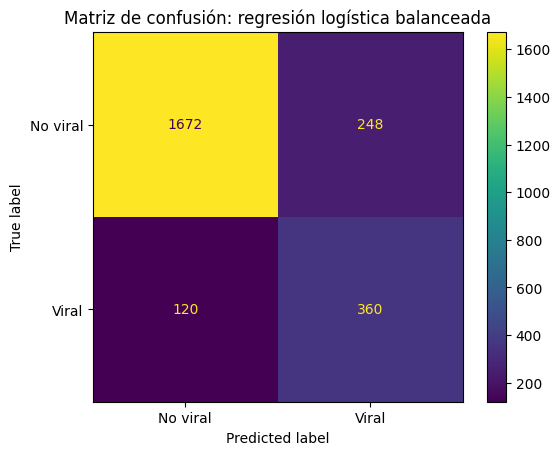

In [68]:
modelo_bal = LogisticRegression(max_iter=1000, class_weight="balanced")  # "balanced" = equivocarse con un viral cuesta más (porque son pocos)
modelo_bal.fit(x_train_esc, y_train)                 # entrena igual que antes
y_pred_bal = modelo_bal.predict(x_test_esc)          # predicciones del modelo balanceado
print(confusion_matrix(y_test, y_pred_bal))          # compara las cajas con las de la celda 8
print("Exactitud:", modelo_bal.score(x_test_esc, y_test))  # puede bajar un poco…
print("Recall:", recall_score(y_test, y_pred_bal))         # …pero debería encontrar más virales

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bal,          # dibuja la matriz como imagen (para tu README)
                                        display_labels=["No viral", "Viral"])
plt.title("Matriz de confusión: regresión logística balanceada")      # título de la gráfica
plt.show()                                                            # muestra la gráfica

In [69]:
from sklearn.tree import DecisionTreeClassifier      # modelo que decide con preguntas tipo "¿suscriptores > 50,000?"

arbol_profundo = DecisionTreeClassifier(random_state=42)   # árbol SIN límite de preguntas
arbol_profundo.fit(x_train, y_train)                       # los árboles no necesitan datos estandarizados
print("Árbol profundo → entrenamiento:", arbol_profundo.score(x_train, y_train),
      "| prueba:", arbol_profundo.score(x_test, y_test))   # entrenamiento ~1.0 y prueba más baja = SOBREAJUSTE (memorizó)

arbol = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)  # máximo 5 preguntas seguidas: no puede memorizar
arbol.fit(x_train, y_train)                                # entrena el árbol limitado
y_pred_arbol = arbol.predict(x_test)                       # predicciones del árbol en el examen
print("Árbol limitado → entrenamiento:", arbol.score(x_train, y_train),
      "| prueba:", arbol.score(x_test, y_test),
      "| recall:", recall_score(y_test, y_pred_arbol))     # compáralo con la regresión logística balanceada

Árbol profundo → entrenamiento: 1.0 | prueba: 0.7920833333333334
Árbol limitado → entrenamiento: 0.7966666666666666 | prueba: 0.7875 | recall: 0.8708333333333333


In [70]:
from sklearn.model_selection import cross_val_score  # repite el entrenamiento y la evaluación varias veces
from sklearn.pipeline import make_pipeline           # une estandarizar + modelo en una sola pieza

pipe = make_pipeline(StandardScaler(),                                        # el estandarizador aprende solo de la parte de estudio en cada vuelta (sin fuga)
                     LogisticRegression(max_iter=1000, class_weight="balanced"))
scores = cross_val_score(pipe, x_train, y_train, cv=5, scoring="recall")      # divide el entrenamiento en 5 partes: entrena con 4, evalúa con 1, y rota
print("Recall en cada vuelta:", scores.round(3))                              # 5 resultados, uno por vuelta
print("Promedio:", scores.mean().round(3), "± desviación:", scores.std().round(3))  # si la desviación es pequeña, el resultado no fue suerte

Recall en cada vuelta: [0.703 0.685 0.716 0.737 0.76 ]
Promedio: 0.72 ± desviación: 0.026
